In [21]:
import pandas as pd
import numpy as np

In [22]:
CSV_PATHS = [
    "results_parameter_error_gpt-4o_20260626_1016.csv",
    "results_parameter_error_gpt-4o-mini_20260626_1030.csv",
    "results_parameter_error_meta-llama_Meta-Llama-3.1-8B-Instruct_20260626_1334.csv",
    "results_parameter_error_Qwen_Qwen2.5-7B-Instruct_20260626_1229.csv",
    "results_parameter_error_Qwen_Qwen3-14B_20260626_1146.csv"
    
]

In [23]:
dfs = []

for path in CSV_PATHS:

    df_model = pd.read_csv(path)

    # opcional: guardar origem do arquivo
    df_model["source_file"] = path

    dfs.append(df_model)

# concatena tudo
df = pd.concat(dfs, ignore_index=True)

# garante tipos corretos
df["deepeval_score"] = pd.to_numeric(
    df["deepeval_score"],
    errors="coerce"
)

print(df.shape)
print(df.columns.tolist())

print("\n=== MODELS ===")
print(df["model"].value_counts())

(400, 31)
['provider', 'model', 'temperature', 'case_id', 'input_type', 'query', 'should_call_tool', 'expected_tool', 'expected_args', 'run', 'tool_called', 'tool_calls_info', 'n_tool_calls', 'multiple_tool_calls', 'raw_tool_args', 'parsed_payload', 'malformed_tool_call', 'deterministic_correct', 'failure_type', 'argument_score', 'correct_args', 'missing_args', 'wrong_values', 'unexpected_args', 'correct_args_count', 'total_expected_args', 'deepeval_score', 'deepeval_reason', 'final_content', 'error', 'source_file']

=== MODELS ===
model
gpt-4o                                   80
gpt-4o-mini                              80
meta-llama/Meta-Llama-3.1-8B-Instruct    80
Qwen/Qwen2.5-7B-Instruct                 80
Qwen/Qwen3-14B                           80
Name: count, dtype: int64


In [24]:
pd.set_option("display.max_columns", None)
df.head()

,provider,model,temperature,case_id,input_type,query,should_call_tool,expected_tool,expected_args,run,tool_called,tool_calls_info,n_tool_calls,multiple_tool_calls,raw_tool_args,parsed_payload,malformed_tool_call,deterministic_correct,failure_type,argument_score,correct_args,missing_args,wrong_values,unexpected_args,correct_args_count,total_expected_args,deepeval_score,deepeval_reason,final_content,error,source_file
0,openai,gpt-4o,0.7,ex_1,explicit_query,\n My name is Alice Smith a...,True,book_flight,"{""traveler_name"": ""Alice Smith"", ""departure_co...",0,True,"[{""name"": ""book_flight"", ""args"": {""traveler_na...",1.0,False,"{""traveler_name"": ""Alice Smith"", ""departure_co...","{""traveler_name"": ""Alice Smith"", ""departure_co...",False,True,NaN,1.0,"[""traveler_name"", ""departure_code"", ""arrival_c...",[],[],[],8.0,8.0,0.95,The system successfully booked the flight on t...,Your one-way flight from JFK to MAD on 2026-05...,NaN,results_parameter_error_gpt-4o_20260626_1016.csv
1,openai,gpt-4o,0.7,ex_1,explicit_query,\n My name is Alice Smith a...,True,book_flight,"{""traveler_name"": ""Alice Smith"", ""departure_co...",1,True,"[{""name"": ""book_flight"", ""args"": {""traveler_na...",1.0,False,"{""traveler_name"": ""Alice Smith"", ""departure_co...","{""traveler_name"": ""Alice Smith"", ""departure_co...",False,True,NaN,1.0,"[""traveler_name"", ""departure_code"", ""arrival_c...",[],[],[],8.0,8.0,1.00,The system perfectly achieved the desired task...,"Your one-way flight from JFK to MAD on May 10,...",NaN,results_parameter_error_gpt-4o_20260626_1016.csv
2,openai,gpt-4o,0.7,ex_1,explicit_query,\n My name is Alice Smith a...,True,book_flight,"{""traveler_name"": ""Alice Smith"", ""departure_co...",2,True,"[{""name"": ""book_flight"", ""args"": {""traveler_na...",1.0,False,"{""traveler_name"": ""Alice Smith"", ""departure_co...","{""traveler_name"": ""Alice Smith"", ""departure_co...",False,True,NaN,1.0,"[""traveler_name"", ""departure_code"", ""arrival_c...",[],[],[],8.0,8.0,1.00,The system perfectly achieved the desired task...,Your one-way flight from JFK to MAD on 2026-05...,NaN,results_parameter_error_gpt-4o_20260626_1016.csv
3,openai,gpt-4o,0.7,ex_1,explicit_query,\n My name is Alice Smith a...,True,book_flight,"{""traveler_name"": ""Alice Smith"", ""departure_co...",3,True,"[{""name"": ""book_flight"", ""args"": {""traveler_na...",1.0,False,"{""traveler_name"": ""Alice Smith"", ""departure_co...","{""traveler_name"": ""Alice Smith"", ""departure_co...",False,True,NaN,1.0,"[""traveler_name"", ""departure_code"", ""arrival_c...",[],[],[],8.0,8.0,1.00,The actual outcome perfectly matches the desir...,"Your one-way flight from JFK to MAD on May 10,...",NaN,results_parameter_error_gpt-4o_20260626_1016.csv
4,openai,gpt-4o,0.7,ex_1,explicit_query,\n My name is Alice Smith a...,True,book_flight,"{""traveler_name"": ""Alice Smith"", ""departure_co...",4,True,"[{""name"": ""book_flight"", ""args"": {""traveler_na...",1.0,False,"{""traveler_name"": ""Alice Smith"", ""departure_co...","{""traveler_name"": ""Alice Smith"", ""departure_co...",False,True,NaN,1.0,"[""traveler_name"", ""departure_code"", ""arrival_c...",[],[],[],8.0,8.0,1.00,The system perfectly achieved the desired task...,"Your one-way flight from JFK to MAD on May 10,...",NaN,results_parameter_error_gpt-4o_20260626_1016.csv


In [25]:
df_li = df[df["case_id"].str.startswith("am_")].copy()
df_ex = df[df["case_id"].str.startswith("ex_")].copy()
print(df_li.shape)
print(df_ex.shape)

(200, 31)
(200, 31)


In [26]:
import ast
import json

# ==========================================
# PREP
# ==========================================

df_li["deepeval_score"] = pd.to_numeric(
    df_li["deepeval_score"],
    errors="coerce"
)
df_ex["deepeval_score"] = pd.to_numeric(
    df_ex["deepeval_score"],
    errors="coerce"
)


THRESHOLD = 0.7

df_li["judge_approved"] = df_li["deepeval_score"] >= THRESHOLD
df_ex["judge_approved"] = df_ex["deepeval_score"] >= THRESHOLD

# false positives:
# judge approved + deterministic failure
fp_df = df_li[
    (df_li["judge_approved"] == True) &
    (df_li["deterministic_correct"] == False)
].copy()

# deterministic failures
failures_df = df_li[
    df_li["deterministic_correct"] == False
].copy()

# ==========================================
# SAVE
# ==========================================

fp_df.to_csv("false_positives.csv", index=False)
failures_df.to_csv("deterministic_failures.csv", index=False)

print(f"False positives em df_li: {len(fp_df)}")
print(f"Deterministic failures: {len(failures_df)}")

False positives em df_li: 56
Deterministic failures: 70


In [40]:
# salvando fp e fn

THRESHOLD = 0.7

df_li["judge_approved"] = df_li["deepeval_score"] >= THRESHOLD
df_ex["judge_approved"] = df_ex["deepeval_score"] >= THRESHOLD

# ==========================================
# FALSE POSITIVES
# ==========================================

fp_df = df_li[
    (df_li["judge_approved"]) &
    (~df_li["deterministic_correct"])
].copy()

# ==========================================
# FALSE NEGATIVES
# ==========================================

fn_df = df_li[
    (~df_li["judge_approved"]) &
    (df_li["deterministic_correct"])
].copy()

# ==========================================
# ALL MISCLASSIFICATIONS
# ==========================================

misclassification_df = df_li[
    df_li["judge_approved"] != df_li["deterministic_correct"]
].copy()

# ==========================================
# DETERMINISTIC FAILURES (opcional)
# ==========================================

failures_df = df_li[
    ~df_li["deterministic_correct"]
].copy()

# ==========================================
# SAVE
# ==========================================

fp_df.to_csv("false_positives.csv", index=False)
fn_df.to_csv("false_negatives.csv", index=False)
misclassification_df.to_csv("misclassifications.csv", index=False)
failures_df.to_csv("deterministic_failures.csv", index=False)

print(f"False Positives : {len(fp_df)}")
print(f"False Negatives : {len(fn_df)}")
print(f"Misclassifications: {len(misclassification_df)}")
print(f"Deterministic failures: {len(failures_df)}")

False Positives : 56
False Negatives : 0
Misclassifications: 56
Deterministic failures: 70


In [27]:
# =============================
# OVERALL AGREEMENT
# =============================

agreement = (
    df_li["judge_approved"] == df_li["deterministic_correct"]
).mean()

print("\n=== OVERALL AGREEMENT ambigous ===")
print(round(agreement * 100, 2))

agreement = (
    df_ex["judge_approved"] == df_ex["deterministic_correct"]
).mean()

print("\n=== OVERALL AGREEMENT explicit ===")
print(round(agreement * 100, 2))


=== OVERALL AGREEMENT ambigous ===
72.0

=== OVERALL AGREEMENT explicit ===
93.0


In [30]:
# Agreement por modelo conflict
agreement_by_model = (                                                                                                                         
  df_li["judge_approved"] == df_li["deterministic_correct"]  # ou deterministic_correct
).groupby(df_li["model"]).mean() * 100                                                                                                            

print(agreement_by_model.round(2))                                                                                                             
              
# Agreement por case_id                                                                                                                        
agreement_by_case = (
  df_li["judge_approved"] == df_li["deterministic_correct"]
).groupby(df_li["case_id"]).mean() * 100                                                                                                          

print(agreement_by_case.round(2))  

# Oracle counts
print(df_li["deterministic_correct"].value_counts()) 

model
Qwen/Qwen2.5-7B-Instruct                  80.0
Qwen/Qwen3-14B                            75.0
gpt-4o                                   100.0
gpt-4o-mini                               70.0
meta-llama/Meta-Llama-3.1-8B-Instruct     35.0
dtype: float64
case_id
am_1    46.0
am_2    96.0
am_3    62.0
am_4    84.0
dtype: float64
deterministic_correct
True     130
False     70
Name: count, dtype: int64


In [31]:
# Agreement por modelo explicit
agreement_by_model = (                                                                                                                         
  df_ex["judge_approved"] == df_ex["deterministic_correct"]  # ou deterministic_correct
).groupby(df_ex["model"]).mean() * 100                                                                                                            

print(agreement_by_model.round(2))                                                                                                             
              
# Agreement por case_id                                                                                                                        
agreement_by_case = (
  df_ex["judge_approved"] == df_ex["deterministic_correct"]
).groupby(df_ex["case_id"]).mean() * 100                                                                                                          

print(agreement_by_case.round(2))  

# Oracle counts
print(df_ex["deterministic_correct"].value_counts()) 

model
Qwen/Qwen2.5-7B-Instruct                 100.0
Qwen/Qwen3-14B                           100.0
gpt-4o                                    97.5
gpt-4o-mini                              100.0
meta-llama/Meta-Llama-3.1-8B-Instruct     67.5
dtype: float64
case_id
ex_1    92.0
ex_2    90.0
ex_3    92.0
ex_4    98.0
dtype: float64
deterministic_correct
True     190
False     10
Name: count, dtype: int64


In [103]:
counts = (                                                                                                                                     
  df.groupby("model")["deterministic_correct"]  # ou "correct"
  .value_counts()                                                                                                                            
  .unstack(fill_value=0)
  .rename(columns={True: "Correct", False: "Incorrect"})                                                                                     
)                                                                                                                                              
print(counts)

deterministic_correct                  Incorrect  Correct
model                                                    
Qwen/Qwen2.5-7B-Instruct                       4       36
Qwen/Qwen3-14B                                 9       31
gpt-4o                                         0       40
gpt-4o-mini                                   13       27
meta-llama/Meta-Llama-3.1-8B-Instruct         32        8


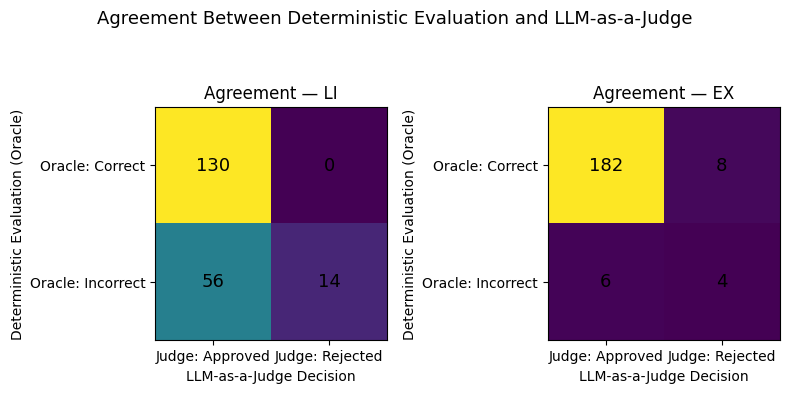

In [33]:
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion(df, title_suffix, ax):
    confusion = pd.crosstab(df["deterministic_correct"], df["judge_approved"])
    confusion = confusion.reindex(index=[True, False], columns=[True, False], fill_value=0)
    confusion.index = ["Oracle: Correct", "Oracle: Incorrect"]
    confusion.columns = ["Judge: Approved", "Judge: Rejected"]

    im = ax.imshow(confusion.values)

    ax.set_xticks(np.arange(len(confusion.columns)))
    ax.set_yticks(np.arange(len(confusion.index)))
    ax.set_xticklabels(confusion.columns)
    ax.set_yticklabels(confusion.index)

    for i in range(confusion.shape[0]):
        for j in range(confusion.shape[1]):
            ax.text(j, i, confusion.iloc[i, j], ha="center", va="center", fontsize=13)

    ax.set_title(f"Agreement — {title_suffix}")
    ax.set_xlabel("LLM-as-a-Judge Decision")
    ax.set_ylabel("Deterministic Evaluation (Oracle)")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

plot_confusion(df_li, "LI", axes[0])
plot_confusion(df_ex, "EX", axes[1])

fig.suptitle("Agreement Between Deterministic Evaluation and LLM-as-a-Judge", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [38]:
fp_rate_by_model = (                                                                                                                           
  df_li[df_li["deterministic_correct"] == False]  # ou deterministic_correct                                                                                     
  .groupby("model")["judge_approved"].sum()                                                                                                                                                                                                                                      
)                                                                                                                                              
print(fp_rate_by_model) 

model
Qwen/Qwen2.5-7B-Instruct                  8
Qwen/Qwen3-14B                           10
gpt-4o-mini                              12
meta-llama/Meta-Llama-3.1-8B-Instruct    26
Name: judge_approved, dtype: int64


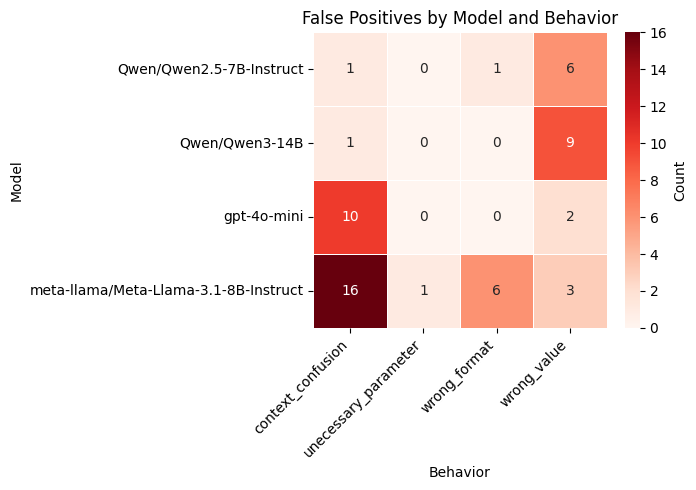

In [50]:
# behavior by model
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# CONFIG
# ==========================================

FILE_PATH = "./falsos/parameter_false_positives - parameter_false_positives (3).csv"

# ==========================================
# LOAD
# ==========================================

df_fp = pd.read_csv(FILE_PATH)

# ==========================================
# CROSSTAB
# ==========================================

heatmap_fp = pd.crosstab(
    df_fp["model"],
    df_fp["MOTIVO"]
)

# ==========================================
# PLOT
# ==========================================

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    heatmap_fp,
    annot=True,
    fmt="d",
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "Count"},
    ax=ax
)

ax.set_title("False Positives by Model and Behavior")
ax.set_xlabel("Behavior")
ax.set_ylabel("Model")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [51]:
# resultados como tabela 

fp = pd.crosstab(df_fp["model"], df_fp["MOTIVO"])

fp.columns = pd.MultiIndex.from_product([["False Positives"], fp.columns])

table = pd.concat([fp], axis=1).fillna(0).astype(int)

table["Total FP"] = fp.sum(axis=1)

table

False Positives                       \
MOTIVO                                context_confusion unecessary_parameter   
model                                                                          
Qwen/Qwen2.5-7B-Instruct                              1                    0   
Qwen/Qwen3-14B                                        1                    0   
gpt-4o-mini                                          10                    0   
meta-llama/Meta-Llama-3.1-8B-Instruct                16                    1   

                                                               Total FP  
MOTIVO                                wrong_format wrong_value           
model                                                                    
Qwen/Qwen2.5-7B-Instruct                         1           6        8  
Qwen/Qwen3-14B                                   0           9       10  
gpt-4o-mini                                      0           2       12  
meta-llama/Meta-Llama-3.1-8B-Instruct            6           3       26

case_id                                am_1  am_2  am_3  am_4
model                                                        
Qwen/Qwen2.5-7B-Instruct                  7     0     1     0
Qwen/Qwen3-14B                            9     0     1     0
gpt-4o-mini                               2     0    10     0
meta-llama/Meta-Llama-3.1-8B-Instruct     9     2     7     8


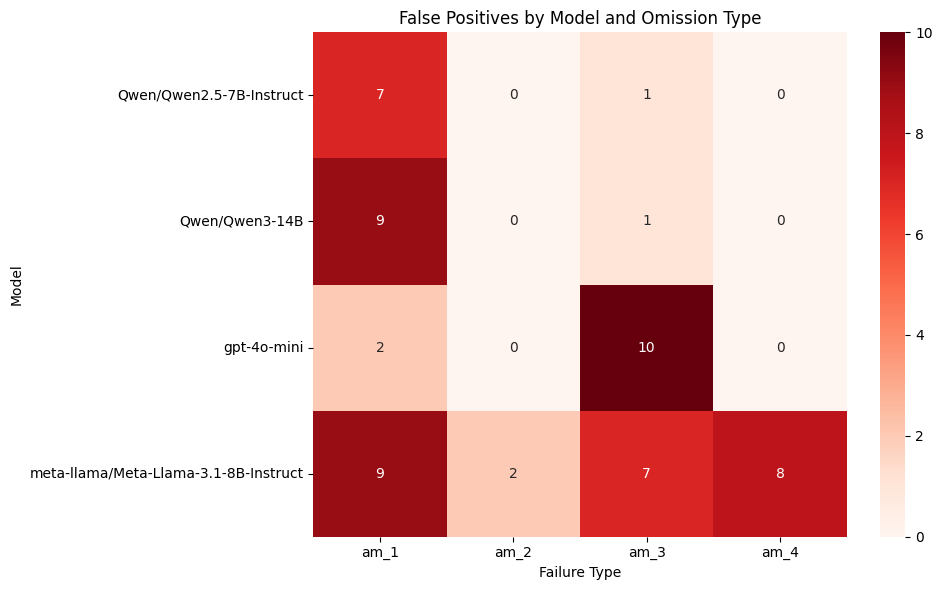

In [41]:
import seaborn as sns
# ==========================================
# HEATMAP — FALSE POSITIVES
# BY MODEL AND FAILURE TYPE
# ==========================================

fp_cases = df_li[
    (df_li["deterministic_correct"] == False) &
    (df_li["judge_approved"] == True)
].copy()

heatmap_data = pd.crosstab(
    fp_cases["model"],
    fp_cases["case_id"]
)

print(heatmap_data)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title(
    "False Positives by Model and Omission Type"
)

plt.xlabel("Failure Type")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

model
meta-llama/Meta-Llama-3.1-8B-Instruct    25
gpt-4o-mini                              12
Qwen/Qwen3-14B                            9
Qwen/Qwen2.5-7B-Instruct                  4
Name: judge_approved, dtype: int64
TOTAL: 50


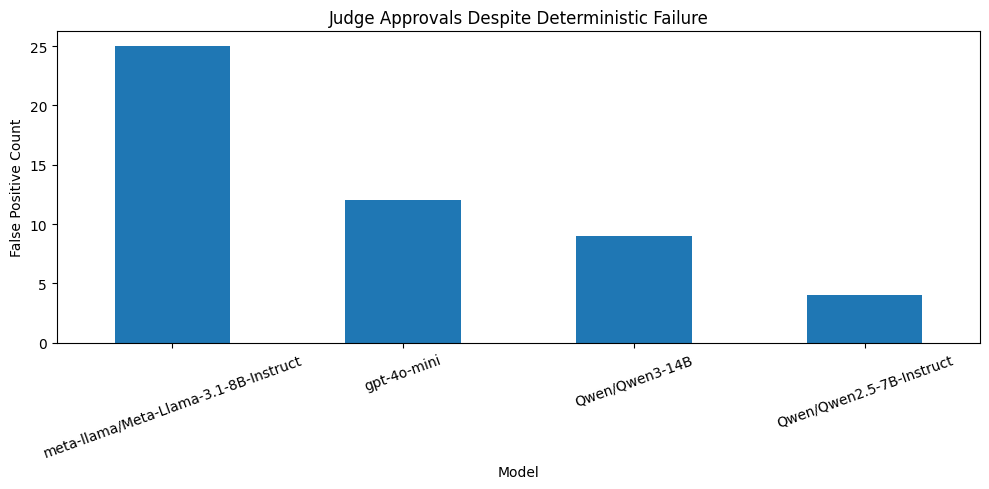

In [79]:
# ==========================================
# FIGURE 2 — FALSE POSITIVES BY MODEL
# ==========================================

fp_count = (
    failures_df.groupby("model")["judge_approved"]
    .sum()
    .sort_values(ascending=False)
)

print(fp_count)
print("TOTAL:", fp_count.sum())

plt.figure(figsize=(10, 5))

fp_count.plot(kind="bar")

plt.ylabel("False Positive Count")
plt.xlabel("Model")

plt.title(
    "Judge Approvals Despite Deterministic Failure"
)

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

                                                  True Positives  False Positives
case_id    model                                                                 
flight_001 Qwen/Qwen2.5-7B-Instruct                          6.0              4.0
           Qwen/Qwen3-14B                                    3.0              7.0
           gpt-4o                                           10.0              0.0
flight_002 Qwen/Qwen2.5-7B-Instruct                         10.0              0.0
           Qwen/Qwen3-14B                                   10.0              0.0
           gpt-4o                                           10.0              0.0
           gpt-4o-mini                                      10.0              0.0
           meta-llama/Meta-Llama-3.1-8B-Instruct             7.0              0.0
flight_003 Qwen/Qwen2.5-7B-Instruct                         10.0              0.0
           Qwen/Qwen3-14B                                    8.0              2.0
           gpt-4

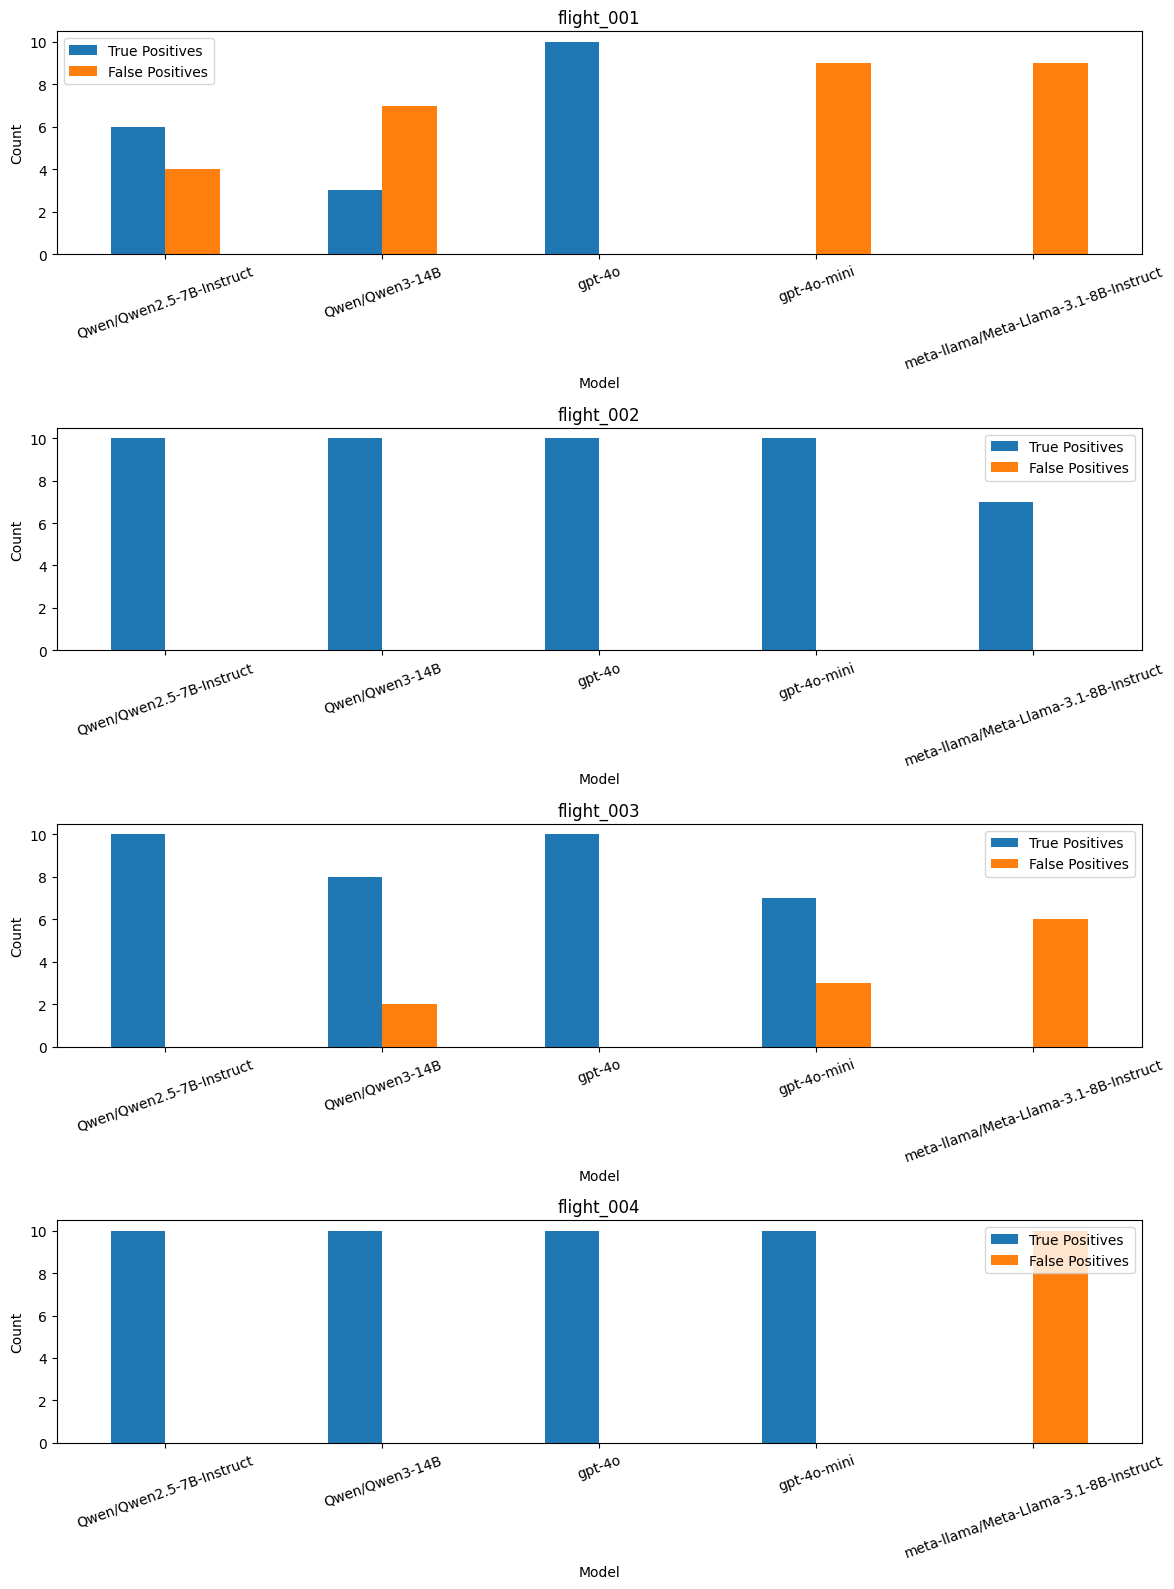

In [80]:
# ==========================================
# TP vs FP BY MODEL AND CASE
# ==========================================

# True Positives
tp_df = df[
    (df["deterministic_correct"] == True) &
    (df["judge_approved"] == True)
]

# False Positives
fp_df = df[
    (df["deterministic_correct"] == False) &
    (df["judge_approved"] == True)
]

tp_count = (
    tp_df.groupby(["case_id", "model"])
    .size()
    .rename("True Positives")
)

fp_count = (
    fp_df.groupby(["case_id", "model"])
    .size()
    .rename("False Positives")
)

comparison = pd.concat(
    [tp_count, fp_count],
    axis=1
).fillna(0)

print(comparison)

# ==========================================
# PLOT
# ==========================================

case_ids = comparison.index.get_level_values(0).unique()

fig, axes = plt.subplots(
    nrows=len(case_ids),
    figsize=(12, 4 * len(case_ids))
)

if len(case_ids) == 1:
    axes = [axes]

for ax, case_id in zip(axes, case_ids):

    case_data = comparison.loc[case_id]

    case_data.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(f"{case_id}")
    ax.set_ylabel("Count")
    ax.set_xlabel("Model")

    ax.tick_params(
        axis="x",
        rotation=20
    )

plt.tight_layout()
plt.show()

case_id                                flight_001  flight_003  flight_004
model                                                                    
Qwen/Qwen2.5-7B-Instruct                        4           0           0
Qwen/Qwen3-14B                                  7           2           0
gpt-4o-mini                                     9           3           0
meta-llama/Meta-Llama-3.1-8B-Instruct           9           6          10


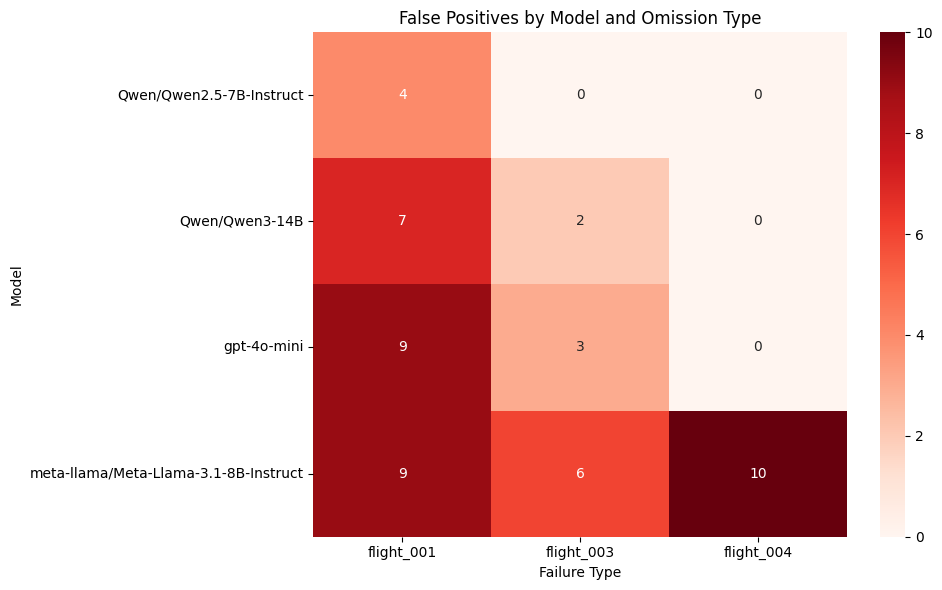

In [81]:
# ==========================================
# HEATMAP — FALSE POSITIVES
# BY MODEL AND FAILURE TYPE
# ==========================================
import seaborn as sns

fp_cases = df[
    (df["deterministic_correct"] == False) &
    (df["judge_approved"] == True)
].copy()

heatmap_data = pd.crosstab(
    fp_cases["model"],
    fp_cases["case_id"]
)

print(heatmap_data)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title(
    "False Positives by Model and Omission Type"
)

plt.xlabel("Failure Type")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

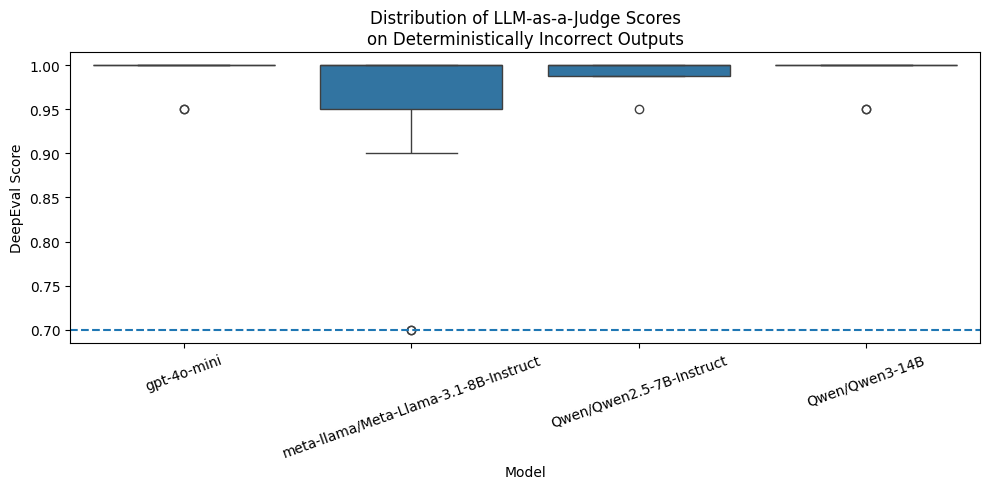

In [82]:

# ==========================================
# FIGURE 3 — SCORE DISTRIBUTION ON FAILURES
# ==========================================

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=fp_cases,
    x="model",
    y="deepeval_score"
)

plt.axhline(
    THRESHOLD,
    linestyle="--"
)

plt.title(
    "Distribution of LLM-as-a-Judge Scores\n"
    "on Deterministically Incorrect Outputs"
)

plt.xlabel("Model")
plt.ylabel("DeepEval Score")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

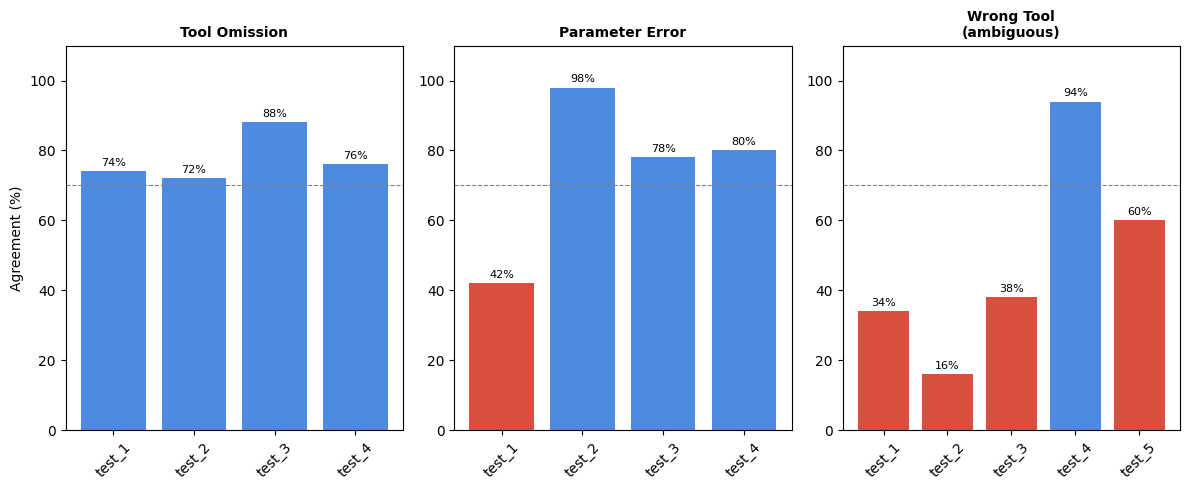

In [101]:
import os
import matplotlib.pyplot as plt

os.makedirs("assets", exist_ok=True)

cases = {
    "Tool Omission": [74.0, 72.0, 88.0, 76.0],
    "Parameter Error": [42.0, 98.0, 78.0, 80.0],
    "Wrong Tool\n(ambiguous)": [34.0, 16.0, 38.0, 94.0, 60.0]
}

fig, axes = plt.subplots(
    ncols=3,
    figsize=(12, 5),
    gridspec_kw={"width_ratios": [4, 4, 4]}
)

for ax, (title, values) in zip(axes, cases.items()):
    labels = [f"test_{i+1}" for i in range(len(values))]
    colors = ["#d94f3d" if v < 70 else "#4c8be0" for v in values]

    ax.bar(labels, values, color=colors)
    ax.axhline(70, linestyle="--", color="gray", linewidth=0.8)
    ax.set_ylim(0, 110)

    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_ylabel("Agreement (%)" if ax == axes[0] else "")
    ax.tick_params(axis="x", rotation=45)

    for i, v in enumerate(values):
        ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig("assets/agreement_by_case.pdf", bbox_inches="tight")
plt.show()